# Fisheries Production and Market Analysis in India

**EDAV Project**

This project analyzes fisheries production across 28 Indian states, comparing coastal and inland regions, species, monthly trends, and market prices.

- **State dataset:** One row per state, with average monthly production for 2022–2023. Nine inland states contain estimated values.
- **Monthly dataset:** Simulated production and price data for 2022–2023, used to demonstrate time-series and market analysis. Values are illustrative, not official statistics.

## 1. Import Libraries

In [ ]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 6)

## 2. Load Dataset

In [ ]:
# upload FISHY.csv
try:
    from google.colab import files
    uploaded = files.upload()
    csv_name = next(iter(uploaded))
    raw= pd.read_csv(io.BytesIO(uploaded[csv_name]))
except ImportError:
    raw = pd.read_csv("FISHY.csv")

display(raw)

Saving FISHY.csv to FISHY (4).csv


,State,Type,Rohu,Catla,Tilapia,Mrigal,Silver_Carp,Pangas,Pomfret,Sardine,Mackerel,Shrimp,Tuna,Hilsa,Total_Tonnes,Is_Estimated
0,Andhra Pradesh,Coastal,133.1,96.9,140.5,147.2,73.0,90.5,126.2,114.4,121.1,99.1,144.0,142.4,1428.4,False
1,Arunachal Pradesh,Inland,114.2,121.5,103.2,114.6,120.0,118.9,0.0,0.0,0.0,0.0,0.0,0.0,692.5,True
2,Assam,Inland,140.8,79.5,131.7,130.7,107.2,85.3,0.0,0.0,0.0,0.0,0.0,0.0,675.1,False
3,Bihar,Inland,95.7,129.9,129.2,161.4,142.1,132.6,0.0,0.0,0.0,0.0,0.0,0.0,790.9,False
4,Chhattisgarh,Inland,119.8,123.5,104.5,137.4,112.1,95.1,0.0,0.0,0.0,0.0,0.0,0.0,692.4,False
5,Goa,Coastal,87.3,96.4,132.9,99.4,114.1,156.0,114.2,141.7,95.6,113.9,98.7,111.9,1362.2,False
6,Gujarat,Coastal,126.3,149.0,128.5,98.6,134.3,96.7,143.6,121.1,116.8,104.8,154.2,119.5,1493.5,False
7,Haryana,Inland,68.3,119.6,101.6,92.2,102.9,114.2,0.0,0.0,0.0,0.0,0.0,0.0,598.9,False
8,Himachal Pradesh,Inland,110.7,117.8,100.0,111.1,116.3,115.2,0.0,0.0,0.0,0.0,0.0,0.0,671.1,True
9,Jammu and Kashmir,Inland,122.4,130.3,110.6,122.9,128.7,127.5,0.0,0.0,0.0,0.0,0.0,0.0,742.5,True


## 3. View Dataset

In [ ]:
print("Rows and columns:", raw.shape)
print("Unique states:", raw["State"].nunique())
display(raw.head(10))
display(raw.dtypes.to_frame("Data type"))

Rows and columns: (29, 16)
Unique states: 29


,State,Type,Rohu,Catla,Tilapia,Mrigal,Silver_Carp,Pangas,Pomfret,Sardine,Mackerel,Shrimp,Tuna,Hilsa,Total_Tonnes,Is_Estimated
0,Andhra Pradesh,Coastal,133.1,96.9,140.5,147.2,73.0,90.5,126.2,114.4,121.1,99.1,144.0,142.4,1428.4,False
1,Arunachal Pradesh,Inland,114.2,121.5,103.2,114.6,120.0,118.9,0.0,0.0,0.0,0.0,0.0,0.0,692.5,True
2,Assam,Inland,140.8,79.5,131.7,130.7,107.2,85.3,0.0,0.0,0.0,0.0,0.0,0.0,675.1,False
3,Bihar,Inland,95.7,129.9,129.2,161.4,142.1,132.6,0.0,0.0,0.0,0.0,0.0,0.0,790.9,False
4,Chhattisgarh,Inland,119.8,123.5,104.5,137.4,112.1,95.1,0.0,0.0,0.0,0.0,0.0,0.0,692.4,False
5,Goa,Coastal,87.3,96.4,132.9,99.4,114.1,156.0,114.2,141.7,95.6,113.9,98.7,111.9,1362.2,False
6,Gujarat,Coastal,126.3,149.0,128.5,98.6,134.3,96.7,143.6,121.1,116.8,104.8,154.2,119.5,1493.5,False
7,Haryana,Inland,68.3,119.6,101.6,92.2,102.9,114.2,0.0,0.0,0.0,0.0,0.0,0.0,598.9,False
8,Himachal Pradesh,Inland,110.7,117.8,100.0,111.1,116.3,115.2,0.0,0.0,0.0,0.0,0.0,0.0,671.1,True
9,Jammu and Kashmir,Inland,122.4,130.3,110.6,122.9,128.7,127.5,0.0,0.0,0.0,0.0,0.0,0.0,742.5,True


,Data type
State,object
Type,object
Rohu,float64
Catla,float64
Tilapia,float64
Mrigal,float64
Silver_Carp,float64
Pangas,float64
Pomfret,float64
Sardine,float64


## 4. Data Cleaning

In [ ]:
data = raw.copy()
data.columns = data.columns.str.strip()
data["State"] = data["State"].astype("string").str.strip()
data["Type"] = data["Type"].astype("string").str.strip().str.title()
data["Is_Estimated"] = data["Is_Estimated"].astype(bool)

numeric_cols = data.select_dtypes(include="number").columns.tolist()
for col in numeric_cols:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.drop_duplicates(subset="State").sort_values("State").reset_index(drop=True)
print("Shape after cleaning:", data.shape)
print("States represented once:", data["State"].is_unique)
print("Estimated states:", data.loc[data["Is_Estimated"], "State"].tolist())
display(data.isna().sum().to_frame("Missing values"))

Shape after cleaning: (29, 16)
States represented once: True
Estimated states: ['Arunachal Pradesh', 'Himachal Pradesh', 'Jammu and Kashmir', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Sikkim', 'Uttarakhand']


,Missing values
State,0
Type,0
Rohu,0
Catla,0
Tilapia,0
Mrigal,0
Silver_Carp,0
Pangas,0
Pomfret,0
Sardine,0


### Missing Values

In [ ]:
missing = data.isna().sum().sort_values(ascending=False)
display(missing.to_frame("Missing values"))

,Missing values
State,0
Type,0
Rohu,0
Catla,0
Tilapia,0
Mrigal,0
Silver_Carp,0
Pangas,0
Pomfret,0
Sardine,0


## 5. Prepare Data

In [ ]:
species_cols = [c for c in data.columns if c not in ["State", "Type", "Total_Tonnes", "Is_Estimated"]]
freshwater_cols = ["Rohu", "Catla", "Tilapia", "Mrigal", "Silver_Carp", "Pangas"]
marine_cols = ["Pomfret", "Sardine", "Mackerel", "Shrimp", "Tuna", "Hilsa"]
data["Freshwater_Tonnes"] = data[freshwater_cols].sum(axis=1)
data["Marine_Tonnes"] = data[marine_cols].sum(axis=1)

print("State categories:")
display(data["Type"].value_counts().to_frame("Number of states"))
print("Species columns:", species_cols)

State categories:


,Number of states
Type,
Inland,20
Coastal,9


Species columns: ['Rohu', 'Catla', 'Tilapia', 'Mrigal', 'Silver_Carp', 'Pangas', 'Pomfret', 'Sardine', 'Mackerel', 'Shrimp', 'Tuna', 'Hilsa']


## 6. NumPy Operations

In [ ]:
production_1d = data["Total_Tonnes"].dropna().to_numpy()
production_2d = data[species_cols].to_numpy(dtype=float)

print("1D array shape:", production_1d.shape)
print("2D array shape (states x species):", production_2d.shape)
print("Mean of state-level average production:", np.nanmean(production_1d).round(2))
print("Maximum species value:", np.nanmax(production_2d).round(2))

1D array shape: (29,)
2D array shape (states x species): (29, 12)
Mean of state-level average production: 943.29
Maximum species value: 178.2


## 7. Advanced NumPy

In [ ]:
print("Transposed shape:", production_2d.T.shape)
flat_values = production_2d.ravel()
print("Flattened array length:", len(flat_values))
print("First 10 flattened values:", flat_values[:10])

Transposed shape: (12, 29)
Flattened array length: 348
First 10 flattened values: [133.1  96.9 140.5 147.2  73.   90.5 126.2 114.4 121.1  99.1]


## 8. Pandas Operations

In [ ]:
print("Series type:", type(data["Total_Tonnes"]))
print("DataFrame type:", type(data))
display(data[["State", "Type", "Total_Tonnes"]].sort_values("Total_Tonnes", ascending=False))

Series type: <class 'pandas.core.series.Series'>
DataFrame type: <class 'pandas.core.frame.DataFrame'>


,State,Type,Total_Tonnes
12,Kerala,Coastal,1545.2
23,Tamil Nadu,Coastal,1498.7
6,Gujarat,Coastal,1493.5
28,West Bengal,Coastal,1473.4
14,Maharashtra,Coastal,1457.5
0,Andhra Pradesh,Coastal,1428.4
19,Odisha,Coastal,1406.5
11,Karnataka,Coastal,1375.9
5,Goa,Coastal,1362.2
10,Jharkhand,Inland,837.7


## 9. Data Transformation

In [ ]:
long_data = data.melt(
    id_vars=["State", "Type"],
    value_vars=species_cols,
    var_name="Species",
    value_name="Average_Monthly_Production"
)
display(long_data.head(10))

,State,Type,Species,Average_Monthly_Production
0,Andhra Pradesh,Coastal,Rohu,133.1
1,Arunachal Pradesh,Inland,Rohu,114.2
2,Assam,Inland,Rohu,140.8
3,Bihar,Inland,Rohu,95.7
4,Chhattisgarh,Inland,Rohu,119.8
5,Goa,Coastal,Rohu,87.3
6,Gujarat,Coastal,Rohu,126.3
7,Haryana,Inland,Rohu,68.3
8,Himachal Pradesh,Inland,Rohu,110.7
9,Jammu and Kashmir,Inland,Rohu,122.4


## 10. GroupBy and Aggregation

In [ ]:
type_summary = data.groupby("Type", as_index=False).agg(
    States=("State", "nunique"),
    Mean_Production=("Total_Tonnes", "mean"),
    Median_Production=("Total_Tonnes", "median")
)
species_summary = long_data.groupby("Species", as_index=False).agg(
    Average_Production=("Average_Monthly_Production", "mean"),
    Highest_State_Value=("Average_Monthly_Production", "max")
).sort_values("Average_Production", ascending=False)
display(type_summary.round(2))
display(species_summary.round(2))

,Type,States,Mean_Production,Median_Production
0,Coastal,9,1449.03,1457.5
1,Inland,20,715.70,709.4


,Species,Average_Production,Highest_State_Value
4,Pangas,123.38,158.5
0,Catla,123.13,158.9
9,Silver_Carp,122.38,147.3
3,Mrigal,121.24,161.4
6,Rohu,115.32,154.6
10,Tilapia,112.50,140.5
5,Pomfret,40.17,178.2
1,Hilsa,37.99,155.3
2,Mackerel,37.10,145.0
7,Sardine,36.93,141.7


## 11. Indexing, Merge and Pivot

In [ ]:
indexed_data = data.set_index(["Type", "State"]).sort_index()
display(indexed_data.head(8))

state_species_pivot = long_data.pivot_table(
    index="State", columns="Species", values="Average_Monthly_Production", aggfunc="mean"
)
display(state_species_pivot.head())

Rohu  Catla  Tilapia  Mrigal  Silver_Carp  Pangas  \
Type    State                                                                
Coastal Andhra Pradesh  133.1   96.9    140.5   147.2         73.0    90.5   
        Goa              87.3   96.4    132.9    99.4        114.1   156.0   
        Gujarat         126.3  149.0    128.5    98.6        134.3    96.7   
        Karnataka        93.5  132.7    108.9   124.7        133.6   129.5   
        Kerala          111.0  112.4    134.3   129.0        132.1   132.2   
        Maharashtra      99.6  137.4    125.8   140.2        110.0   123.6   
        Odisha           77.7  112.2    126.2   134.0        141.4   143.9   
        Tamil Nadu      121.4   99.3    102.3   136.6        142.4   134.4   

                        Pomfret  Sardine  Mackerel  Shrimp   Tuna  Hilsa  \
Type    State                                                              
Coastal Andhra Pradesh    126.2    114.4     121.1    99.1  144.0  142.4   
        Goa               114.2    141.7      95.6   113.9   98.7  111.9   
        Gujarat           143.6    121.1     116.8   104.8  154.2  119.5   
        Karnataka         136.9    121.0     110.1   119.8   80.5   84.7   
        Kerala            178.2    112.5     109.3   101.0  137.9  155.3   
        Maharashtra       136.2    114.5     133.0   105.7  114.4  117.2   
        Odisha            112.3    111.3     145.0   118.9   90.9   92.8   
        Tamil Nadu        106.6    127.7     126.3   128.9  143.9  128.7   

                        Total_Tonnes  Is_Estimated  Freshwater_Tonnes  \
Type    State                                                           
Coastal Andhra Pradesh        1428.4         False              681.2   
        Goa                   1362.2         False              686.1   
        Gujarat               1493.5         False              733.4   
        Karnataka             1375.9         False              722.9   
        Kerala                1545.2         False              751.0   
        Maharashtra           1457.5         False              736.6   
        Odisha                1406.5         False              735.4   
        Tamil Nadu            1498.7         False              736.4   

                        Marine_Tonnes  
Type    State                          
Coastal Andhra Pradesh          747.2  
        Goa                     676.0  
        Gujarat                 760.0  
        Karnataka               653.0  
        Kerala                  794.2  
        Maharashtra             721.0  
        Odisha                  671.2  
        Tamil Nadu              762.1

Species,Catla,Hilsa,Mackerel,Mrigal,Pangas,Pomfret,Rohu,Sardine,Shrimp,Silver_Carp,Tilapia,Tuna
State,,,,,,,,,,,,
Andhra Pradesh,96.9,142.4,121.1,147.2,90.5,126.2,133.1,114.4,99.1,73.0,140.5,144.0
Arunachal Pradesh,121.5,0.0,0.0,114.6,118.9,0.0,114.2,0.0,0.0,120.0,103.2,0.0
Assam,79.5,0.0,0.0,130.7,85.3,0.0,140.8,0.0,0.0,107.2,131.7,0.0
Bihar,129.9,0.0,0.0,161.4,132.6,0.0,95.7,0.0,0.0,142.1,129.2,0.0
Chhattisgarh,123.5,0.0,0.0,137.4,95.1,0.0,119.8,0.0,0.0,112.1,104.5,0.0


## 12. Matplotlib Graphs

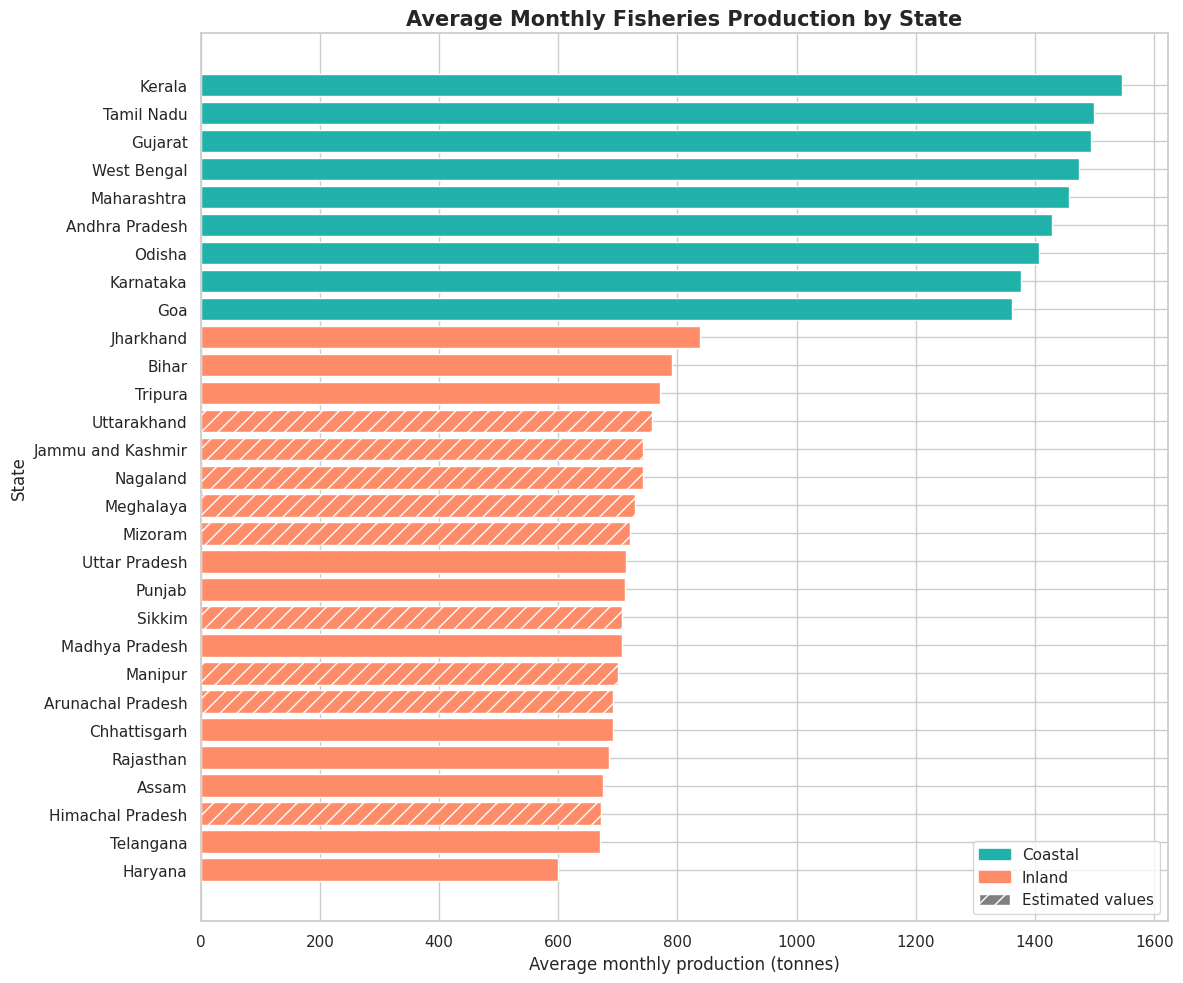

In [ ]:
# Horizontal bar chart coloured by state type; estimated states are hatched
from matplotlib.patches import Patch
state_totals = data.sort_values("Total_Tonnes", ascending=True)
type_colors = {"Coastal": "#20B2AA", "Inland": "#FF8C69"}
plt.figure(figsize=(12, 10))
bars = plt.barh(state_totals["State"], state_totals["Total_Tonnes"],
                color=state_totals["Type"].map(type_colors))
for bar, est in zip(bars, state_totals["Is_Estimated"]):
    if est:
        bar.set_hatch("//")
        bar.set_edgecolor("white")
plt.title("Average Monthly Fisheries Production by State", fontsize=15, weight="bold")
plt.xlabel("Average monthly production (tonnes)")
plt.ylabel("State")
plt.legend(handles=[Patch(color=type_colors["Coastal"], label="Coastal"),
                    Patch(color=type_colors["Inland"], label="Inland"),
                    Patch(facecolor="grey", hatch="//", edgecolor="white", label="Estimated values")],
           loc="lower right")
plt.tight_layout()
plt.show()

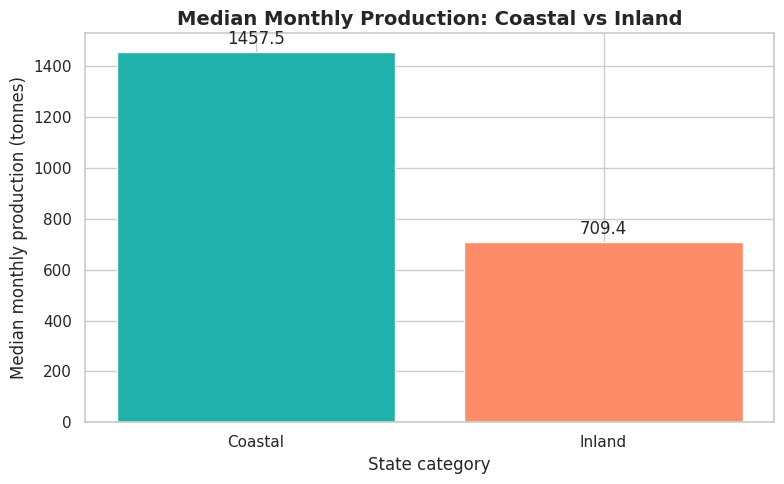

In [ ]:
# Coastal vs inland: median production (less affected by one large state than the mean)
type_med = data.groupby("Type", as_index=False)["Total_Tonnes"].median()
plt.figure(figsize=(8, 5))
bars = plt.bar(type_med["Type"], type_med["Total_Tonnes"], color=[type_colors[t] for t in type_med["Type"]])
plt.title("Median Monthly Production: Coastal vs Inland", fontsize=14, weight="bold")
plt.ylabel("Median monthly production (tonnes)")
plt.xlabel("State category")
plt.bar_label(bars, fmt="%.1f", padding=3)
plt.tight_layout()
plt.show()

## 13. Seaborn Graphs

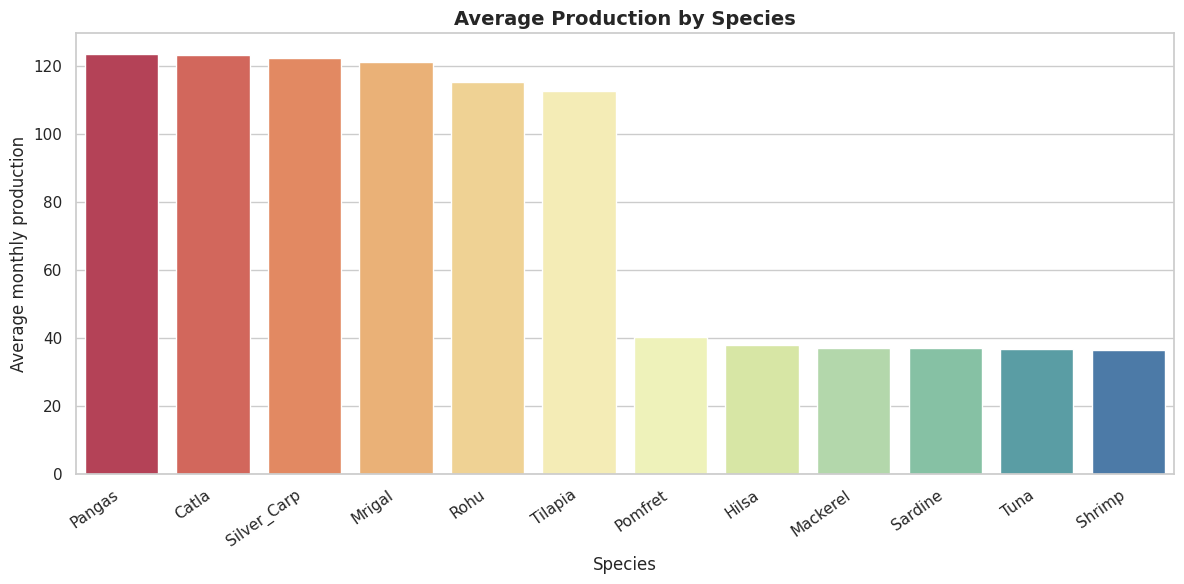

In [ ]:
species_plot = species_summary.sort_values("Average_Production", ascending=False)
plt.figure(figsize=(12, 6))
sns.barplot(data=species_plot, x="Species", y="Average_Production", hue="Species", palette="Spectral", legend=False)
plt.title("Average Production by Species", fontsize=14, weight="bold")
plt.xlabel("Species")
plt.ylabel("Average monthly production")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 15. Heatmap

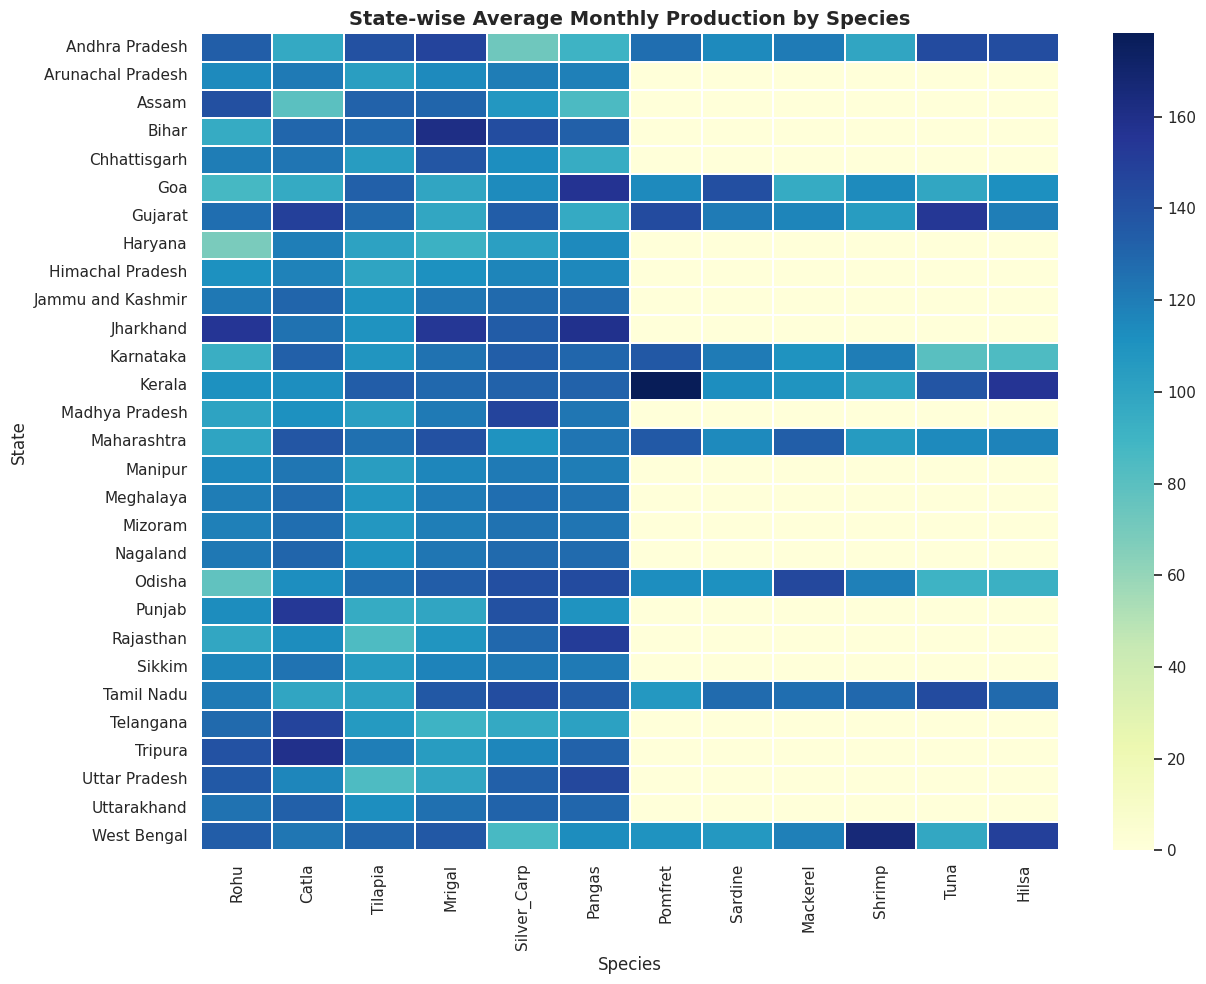

In [ ]:
heatmap_data = data.set_index("State")[species_cols]
plt.figure(figsize=(13, 10))
sns.heatmap(heatmap_data, cmap="YlGnBu", linewidths=0.25, annot=False)
plt.title("State-wise Average Monthly Production by Species", fontsize=14, weight="bold")
plt.xlabel("Species")
plt.ylabel("State")
plt.tight_layout()
plt.show()

## 16. Time Series and Market Analysis

Monthly production and price data (simulated, 2022–2023), merged with the state dataset to get each state's type.

In [ ]:
# In Google Colab, upload fisheries_monthly_simulated.csv when prompted.
try:
    from google.colab import files
    up = files.upload()
    monthly = pd.read_csv(io.BytesIO(up[next(iter(up))]))
except ImportError:
    monthly = pd.read_csv("fisheries_monthly_simulated.csv")

monthly["Month"] = pd.to_datetime(monthly["Month"])
monthly = monthly.merge(data[["State", "Type", "Is_Estimated"]], on="State", how="left")

# Revenue in Rs crore: tonnes x 1000 kg x Rs/kg, divided by 1e7
monthly["Revenue_Cr"] = (monthly["Freshwater_Tonnes"] * monthly["Freshwater_Price_Rs_kg"]
                         + monthly["Marine_Tonnes"].fillna(0) * monthly["Marine_Price_Rs_kg"].fillna(0)) * 1000 / 1e7
monthly["Total_Tonnes_M"] = monthly["Freshwater_Tonnes"] + monthly["Marine_Tonnes"]
print(monthly.shape)
display(monthly.head())

Saving fisheries_monthly_simulated.csv to fisheries_monthly_simulated.csv
(696, 10)


,Month,State,Freshwater_Tonnes,Marine_Tonnes,Freshwater_Price_Rs_kg,Marine_Price_Rs_kg,Type,Is_Estimated,Revenue_Cr,Total_Tonnes_M
0,2022-01-01,Andhra Pradesh,641.9,843.9,182.2,308.8,Coastal,False,37.755050,1485.8
1,2022-02-01,Andhra Pradesh,589.0,847.2,186.1,305.5,Coastal,False,36.843250,1436.2
2,2022-03-01,Andhra Pradesh,653.4,885.5,185.4,310.5,Coastal,False,39.608811,1538.9
3,2022-04-01,Andhra Pradesh,693.0,292.7,170.0,426.8,Coastal,False,24.273436,985.7
4,2022-05-01,Andhra Pradesh,617.3,293.4,175.9,434.3,Coastal,False,23.600669,910.7


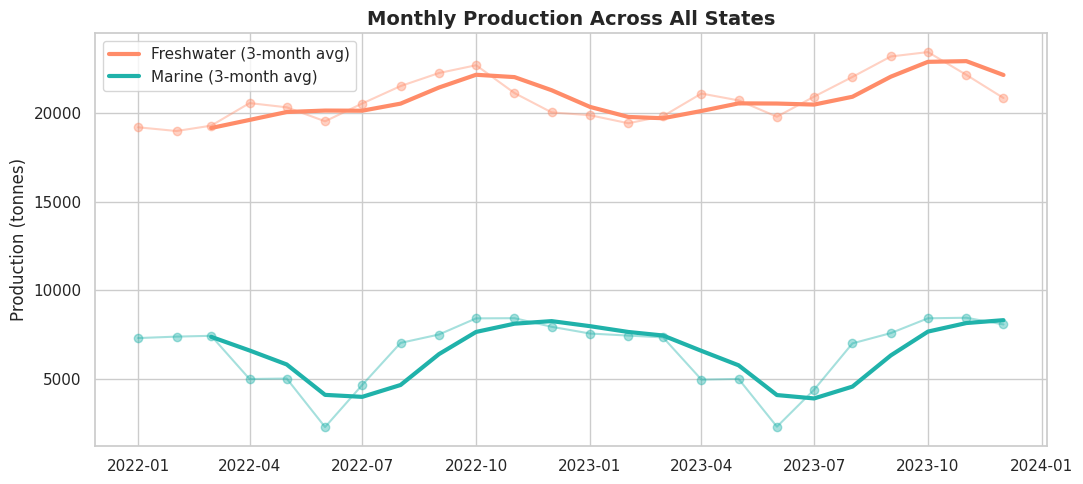

,Freshwater_Tonnes,Marine_Tonnes
Month,,
1,19548.0,7428.0
2,19216.0,7412.0
3,19567.0,7384.0
4,20844.0,4971.0
5,20531.0,5004.0
6,19675.0,2284.0
7,20745.0,4517.0
8,21794.0,7014.0
9,22740.0,7542.0


In [ ]:
# National monthly production: freshwater vs marine, with 3-month rolling average
national = monthly.groupby("Month")[["Freshwater_Tonnes", "Marine_Tonnes"]].sum()
plt.figure(figsize=(11, 5))
for col, color in [("Freshwater_Tonnes", "#FF8C69"), ("Marine_Tonnes", "#20B2AA")]:
    plt.plot(national.index, national[col], marker="o", alpha=0.4, color=color)
    plt.plot(national.index, national[col].rolling(3).mean(), linewidth=3, color=color, label=col.replace("_Tonnes", "") + " (3-month avg)")
plt.title("Monthly Production Across All States", fontsize=14, weight="bold")
plt.ylabel("Production (tonnes)")
plt.legend()
plt.tight_layout()
plt.show()

# Seasonality: average by calendar month
seasonal = monthly.groupby(monthly["Month"].dt.month)[["Freshwater_Tonnes", "Marine_Tonnes"]].sum() / 2
display(seasonal.round(0))

Correlation between monthly production and average price: -0.32


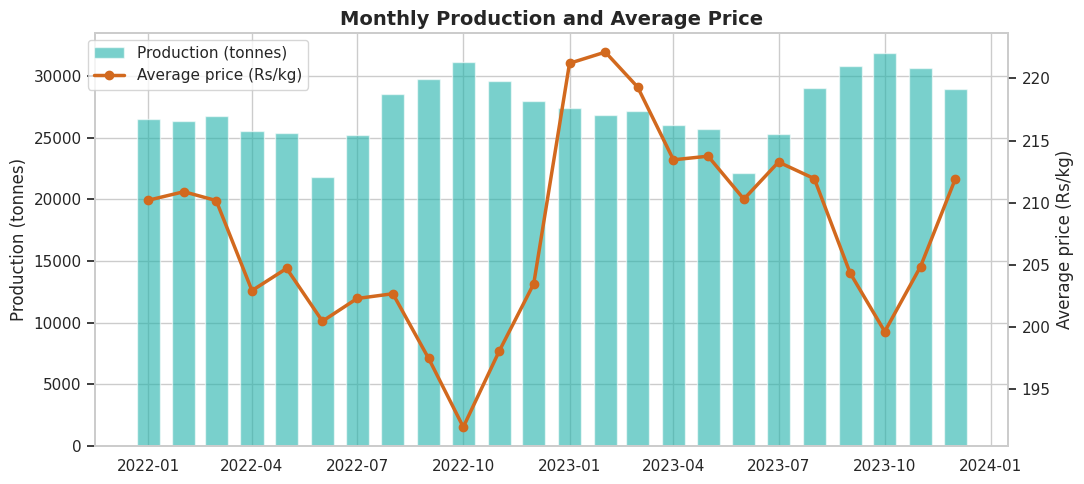

In [ ]:
# Price vs production: weighted average price per kg each month
agg = monthly.groupby("Month").apply(lambda g: pd.Series({
    "Production": g["Total_Tonnes_M"].sum(),
    "Avg_Price": (g["Revenue_Cr"].sum() * 1e7) / (g["Total_Tonnes_M"].sum() * 1000),
    "Revenue_Cr": g["Revenue_Cr"].sum()
}), include_groups=False)
corr = agg["Production"].corr(agg["Avg_Price"])
print("Correlation between monthly production and average price:", round(corr, 2))

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(agg.index, agg["Production"], width=20, color="#20B2AA", alpha=0.6, label="Production (tonnes)")
ax1.set_ylabel("Production (tonnes)")
ax2 = ax1.twinx()
ax2.plot(agg.index, agg["Avg_Price"], color="#D2691E", marker="o", linewidth=2.5, label="Average price (Rs/kg)")
ax2.set_ylabel("Average price (Rs/kg)")
ax2.grid(False)
plt.title("Monthly Production and Average Price", fontsize=14, weight="bold")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.92))
plt.tight_layout()
plt.show()

Type,Coastal,Inland
Year,,
2022,3672.0,2907.0
2023,3909.0,3123.0


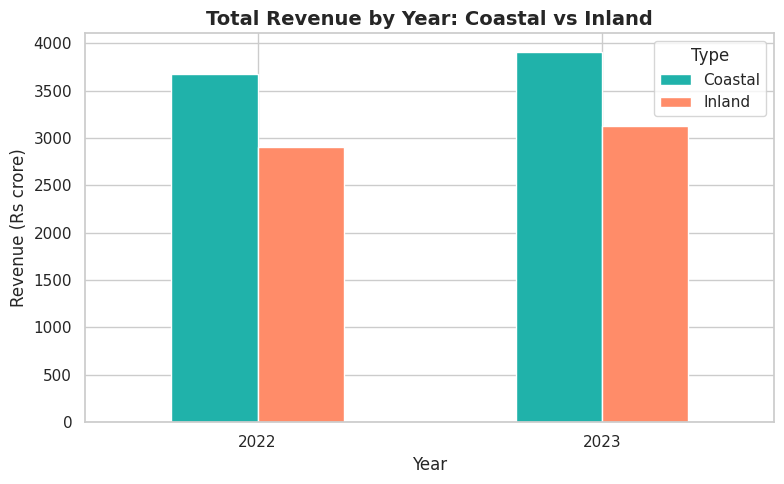

,Total revenue (Rs crore)
State,
Kerala,931.0
Maharashtra,912.0
West Bengal,885.0
Andhra Pradesh,861.0
Tamil Nadu,835.0


In [ ]:
# Revenue: coastal vs inland, and by year
monthly["Year"] = monthly["Month"].dt.year
rev = monthly.groupby(["Year", "Type"])["Revenue_Cr"].sum().unstack()
display(rev.round(0))
rev.plot(kind="bar", color=["#20B2AA", "#FF8C69"], figsize=(8, 5), rot=0)
plt.title("Total Revenue by Year: Coastal vs Inland", fontsize=14, weight="bold")
plt.ylabel("Revenue (Rs crore)")
plt.tight_layout()
plt.show()

top_rev = monthly.groupby("State")["Revenue_Cr"].sum().sort_values(ascending=False).head(5)
display(top_rev.round(0).to_frame("Total revenue (Rs crore)"))

### Time Series and Market Findings

*These come from the simulated monthly data, so they show what the analysis reveals given the seasonal and price patterns built into it, not real market behaviour.*

1. **Marine production is strongly seasonal.** It falls to its lowest in June (about 2,300 tonnes nationally) during the monsoon fishing ban and peaks in October and November (about 8,400 tonnes).
2. **Freshwater production is steadier,** staying between about 19,200 and 23,100 tonnes a month and peaking in October.
3. **Prices tend to move against supply.** The correlation between monthly production and average price is weak and negative (about -0.32), so prices are somewhat higher in low-supply months.
4. **Coastal states earn more total revenue** (about Rs 3,900 crore in 2023 against Rs 3,100 crore for inland), even though the 20 inland states produce slightly more tonnage in total, because marine species sell at higher prices.
5. **Revenue grew about 6–7% from 2022 to 2023** for both groups, which mostly reflects the price increase assumed in the data.

## 17. Results and Insights

In [ ]:
top_state = data.loc[data["Total_Tonnes"].idxmax()]
top_species = species_summary.iloc[0]
print(f"Highest average monthly production: {top_state['State']} ({top_state['Total_Tonnes']:.1f} tonnes)")
print(f"State category: {top_state['Type']}")
print(f"Highest average species value across states: {top_species['Species']} ({top_species['Average_Production']:.1f})")
print("\nAverage monthly production by category:")
display(type_summary.round(2))

Highest average monthly production: Kerala (1545.2 tonnes)
State category: Coastal
Highest average species value across states: Pangas (123.4)

Average monthly production by category:


,Type,States,Mean_Production,Median_Production
0,Coastal,9,1449.03,1457.5
1,Inland,20,715.70,709.4
